# Clasificador de categoría y gravedad de reclamos ciudadanos de Sucre (BETO)

**Objetivo.** Un solo modelo que lee el texto de un reclamo y devuelve **dos respuestas**:

1. **Categoría** (basura, agua, alumbrado, baches, transporte, seguridad, ruidos/ambiente u otros). Sirve para **corroborar** la categoría que eligió el ciudadano o **avisar si se equivocó**.
2. **Gravedad**: `0 · Leve`, `1 · Moderada` o `2 · Grave`. Alimenta el mapa de zonas de prioridad.

**Cómo lo hace.** Es un modelo *multitarea*: una sola base **BETO** (`dccuchile/bert-base-spanish-wwm-cased`, un BERT en español) lee el texto, y sobre su resultado hay **dos cabezas** independientes, una por tarea. Compartir la base es eficiente (se entrena una sola vez) y ayuda: lo que aprende para reconocer la categoría también sirve para entender la gravedad.

**Qué hace la página de administración con esto.** Para cada reclamo compara la categoría del ciudadano con la del modelo:

| Veredicto | Cuándo | Qué hace el sistema |
|---|---|---|
| **coincide** | el modelo predice la misma categoría | la corrobora |
| **posible error** | el modelo predice otra con **confianza alta** | la corrige (configurable) y avisa |
| **dudosa** | el modelo predice otra con confianza baja | deja la del ciudadano y lo manda a revisión manual |

El mapa de cada categoría usará la **categoría final** de este análisis.

**Relación con tus notebooks:** clasificación *many-to-one* y bucle de entrenamiento (02), BERT preentrenado y su tokenizador (03), atención (05).

**Contenido:** 1 Importaciones · 2 Configuración · 3 Carga · 4 Limpieza · 5 Exploración · 6 División · 7 Tokenización · 8 Dataset · 9 Modelo · 10 Pérdidas y optimizador · 11 Funciones · 12 Entrenamiento · 13 Descenso del gradiente · 14 Métricas · 15 Matrices de confusión · 16 Análisis por riesgo y por categoría · 16b Umbral de gravedad · 17 Umbral de confianza · 18 Simulación de errores del ciudadano · 19 Errores del modelo · 20 Inferencia · 21 Guardado · 22 Recarga.

> Cada celda de código tiene arriba una celda de explicación.

## 1. Importaciones

Cargamos **pandas** (tablas), **matplotlib** (gráficos), **PyTorch** (la red), **transformers** (BETO y su tokenizador) y **scikit-learn** (división de datos y métricas). En Colab todo viene instalado; si falta algo, descomenta la línea de `pip`.

In [1]:
# !pip install -q transformers scikit-learn pandas matplotlib

import os, json, random, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score)

print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu


## 2. Configuración

Todos los parámetros están aquí para cambiarlos sin tocar el resto.

- `CATEGORIAS`: las 8 categorías **en un orden fijo**. El modelo las ve como números 0 a 7, así que este orden debe ser el mismo en el entrenamiento y en la página.
- `PESO_LOSS_CAT` / `PESO_LOSS_GRAV`: cuánto pesa cada tarea en la pérdida total. Con 1.0 y 1.0 las dos cuentan igual.
- `MIN_REALES`: si hay al menos esa cantidad de reclamos **reales**, la validación y la prueba se arman **solo con reales**; los sintéticos solo entrenan.
- `PRECISION_OBJETIVO` y `UMBRAL_MIN_CAT`: sirven para decidir a partir de qué confianza el modelo puede decir "el ciudadano se equivocó" (sección 17).
- `AUTOCORREGIR`: si es `True`, cuando hay *posible error* la categoría final es la del modelo; si es `False`, se queda la del ciudadano y solo se avisa.
- `FRAC_ERROR_SIM`: porcentaje de errores del ciudadano que se simulan para probar el verificador (sección 18).
- `CONGELAR_BERT`: `False` ajusta todo el modelo (*fine-tuning*); `True` reproduce el enfoque del notebook 03 (BERT congelado).

- `FRAC_SINTETICOS`: qué fracción de los reclamos **sintéticos** se usa para entrenar. Si el modelo memoriza los textos generados y falla con los reales, bájala (0.3, o 0.0 para entrenar solo con reales).
- `SUAVIZADO`: *label smoothing*; evita que el modelo se vuelva demasiado seguro y reduce el sobreajuste (prueba 0.1).
- `SCORE_GRAVEDAD`: si es `True`, la mejor época se elige solo por el F1 de **gravedad**. Útil cuando la categoría ya está en ~1.0 y no aporta para decidir.

Fijamos las **semillas** para reproducibilidad y elegimos GPU si existe.

In [2]:
# ---------- Modelo preentrenado ----------
MODELO_BASE = "dccuchile/bert-base-spanish-wwm-cased"   # BETO
# Alternativa para comparar: "PlanTL-GOB-ES/roberta-base-bne"  (MarIA)

# ---------- Categorías (orden fijo) ----------
CATEGORIAS = ["Recojo de basura", "Agua y alcantarillado", "Alumbrado público", "Baches y vías",
              "Transporte y tránsito", "Seguridad ciudadana", "Ruidos y medio ambiente", "Otros"]
CAT_CORTO = ["Basura", "Agua", "Alumbrado", "Baches", "Transporte", "Seguridad", "Ruidos/Amb.", "Otros"]
NOMBRES_GRAV = ["0 · Leve", "1 · Moderada", "2 · Grave"]

# ---------- Datos ----------
RUTA_CSV = "C:\\Users\\villa\\Downloads\\reclamos_sucre_app\\reclamos_matias (1).csv"         # CSV exportado por la página de registro
SINTETICO = "sintetico_ejemplo"   # valor de `fuente` que marca los datos sintéticos
MIN_REALES = 100
FRAC_TEST_REAL = 0.25
FRAC_VAL_REAL = 0.15

# ---------- Entrenamiento ----------
MAX_LEN = 128
BATCH = 16
EPOCAS = 20
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP = 0.1
DROPOUT = 0.3
MAX_GRAD_NORM = 1.0
PACIENCIA = 15
CONGELAR_BERT = False
USAR_PESOS_CLASE = True
PESO_LOSS_CAT = 1.0
PESO_LOSS_GRAV = 1.0
FRAC_SINTETICOS = 1.0     # fracción de los reclamos sintéticos usada para entrenar (prueba 0.3 o 0.0)
SUAVIZADO = 0.0           # suavizado de etiquetas; prueba 0.1 para reducir el sobreajuste
SCORE_GRAVEDAD = False    # True = elegir la mejor época solo por el F1 de gravedad
SEMILLA = 42

# ---------- Verificación de la categoría del ciudadano ----------
PRECISION_OBJETIVO = 0.95   # exactitud mínima que queremos cuando el modelo "contradice" al ciudadano
UMBRAL_MIN_CAT = 0.60       # confianza mínima absoluta para llamar "posible error"
AUTOCORREGIR = True
FRAC_ERROR_SIM = 0.15

random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

Dispositivo: cpu


## 3. Carga de datos

Leemos el CSV exportado por la página de registro. En **Colab**, si el archivo no está en la carpeta, se abre un cuadro para subirlo. Usamos `utf-8-sig` porque el CSV lleva una marca (BOM) para que Excel abra bien las tildes.

La única columna imprescindible es `texto`. Además se necesita al menos una de las dos etiquetas: `categoria` y/o `gravedad_humana`. **Un reclamo con solo una de las dos etiquetas también sirve**: entrena la tarea que sí tiene y se ignora la otra. Así aprovechas, por ejemplo, reclamos ya categorizados que todavía no etiquetaste en gravedad.

In [3]:


df = pd.read_csv(r"C:\Users\villa\Downloads\reclamos_sucre_app\reclamos_matias (1).csv", encoding="utf-8-sig")

assert "texto" in df.columns, "El CSV debe tener una columna llamada texto"
assert ("categoria" in df.columns) or ("gravedad_humana" in df.columns), \
    "El CSV debe tener al menos una de las columnas: categoria, gravedad_humana"

print("Filas y columnas:", df.shape)
display(df.head(3))

Filas y columnas: (1320, 12)


,id,texto,categoria,gravedad_humana,justificacion,caso_dificil,barrio,lat,lon,fecha,fuente,etiquetador
0,R001,Dejaron una bolsa de basura sin recoger frente...,Recojo de basura,0.0,"Molestia puntual, sin riesgo",No,NaN,NaN,NaN,NaN,sintetico_ejemplo,plantilla
1,R002,"Los tachos de la plaza están llenos, deberían ...",Recojo de basura,0.0,"Molestia leve, servicio funciona",No,NaN,NaN,NaN,NaN,sintetico_ejemplo,plantilla
2,R003,Hace una semana no pasa el camión de basura po...,Recojo de basura,1.0,"Problema sostenido de salubridad, sin riesgo i...",No,NaN,NaN,NaN,NaN,sintetico_ejemplo,plantilla


## 4. Limpieza

Un modelo es tan bueno como sus datos, así que antes de entrenar:

1. Quitamos textos vacíos o demasiado cortos.
2. **Categoría:** la llevamos al nombre oficial de `CATEGORIAS` (sin importar mayúsculas); lo que no coincida queda vacío.
3. **Gravedad:** solo se aceptan 0, 1 o 2; lo demás queda vacío.
4. Descartamos filas que no tengan **ninguna** de las dos etiquetas.
5. Creamos `y_cat` e `y_grav`: son los números que verá la red. Lo que falta se marca con **-100**, un valor que PyTorch ignora al calcular la pérdida.
6. Eliminamos **textos duplicados**, prefiriendo el real sobre el sintético, para que el mismo texto no caiga en entrenamiento y en prueba.

Igual que antes, **no quitamos tildes ni mayúsculas**: BETO las necesita. Tampoco usamos la categoría como entrada, porque ahora es una de las cosas que el modelo debe predecir.

In [4]:
n_inicial = len(df)

df["texto"] = df["texto"].astype(str).str.strip()
df = df[df["texto"].str.len() >= 10].copy()

# --- categoría: nombre oficial o vacío ---
CAT_MAP = {c.lower(): c for c in CATEGORIAS}
if "categoria" not in df.columns:
    df["categoria"] = np.nan
df["categoria"] = df["categoria"].astype(str).str.strip().str.lower().map(CAT_MAP)

# --- gravedad: 0, 1, 2 o vacío ---
if "gravedad_humana" not in df.columns:
    df["gravedad_humana"] = np.nan
df["gravedad_humana"] = pd.to_numeric(df["gravedad_humana"], errors="coerce")
df.loc[~df["gravedad_humana"].isin([0, 1, 2]), "gravedad_humana"] = np.nan

# --- al menos una etiqueta ---
df = df[df["categoria"].notna() | df["gravedad_humana"].notna()].copy()

for col, defecto in [("fuente", "otro"), ("caso_dificil", "No")]:
    if col not in df.columns:
        df[col] = defecto
    df[col] = df[col].fillna(defecto).astype(str)

# --- etiquetas numéricas para la red (-100 = falta) ---
IDX_CAT = {c: i for i, c in enumerate(CATEGORIAS)}
df["y_cat"] = df["categoria"].map(IDX_CAT).fillna(-100).astype(int)
df["y_grav"] = df["gravedad_humana"].fillna(-100).astype(int)

# --- duplicados (se conserva primero el real) ---
df["_clave"] = df["texto"].str.lower().str.replace(r"\s+", " ", regex=True)
df["_es_sint"] = df["fuente"] == SINTETICO
df = (df.sort_values("_es_sint")
        .drop_duplicates("_clave", keep="first")
        .drop(columns="_clave")
        .reset_index(drop=True))
df["entrada"] = df["texto"]

print(f"Filas originales: {n_inicial}  ->  válidas y únicas: {len(df)}")
print(f"Reales: {(~df['_es_sint']).sum()}  |  Sintéticas: {df['_es_sint'].sum()}")
print(f"Con categoría: {(df['y_cat'] >= 0).sum()}  |  Con gravedad: {(df['y_grav'] >= 0).sum()}  "
      f"|  Con ambas: {((df['y_cat'] >= 0) & (df['y_grav'] >= 0)).sum()}")

Filas originales: 1320  ->  válidas y únicas: 1320
Reales: 223  |  Sintéticas: 1097
Con categoría: 1320  |  Con gravedad: 1002  |  Con ambas: 1002


## 5. Exploración de los datos

Miramos cómo están repartidas las clases de **cada tarea**. Una categoría o gravedad con muy pocos ejemplos se aprenderá mal; por eso usamos pesos por clase en la pérdida (sección 10).

La tabla cruzada muestra cuántos reclamos hay por categoría y gravedad (solo filas con ambas etiquetas): sirve para comprobar que cada categoría tiene ejemplos de las tres gravedades.

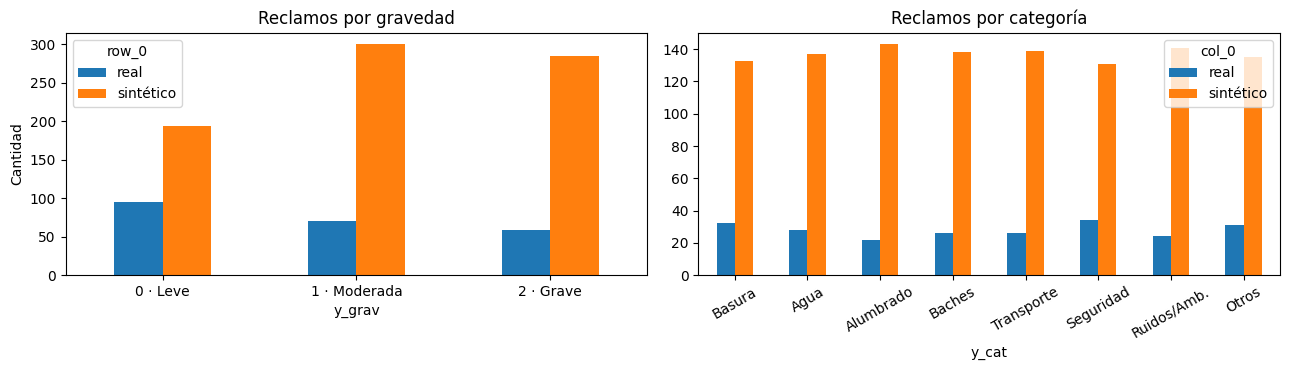

Categoría x gravedad (filas con ambas etiquetas):


y_grav,0 · Leve,1 · Moderada,2 · Grave
categoria,,,
Agua y alcantarillado,40,45,37
Alumbrado público,36,50,36
Baches y vías,37,51,25
Otros,37,52,40
Recojo de basura,28,43,59
Ruidos y medio ambiente,36,38,53
Seguridad ciudadana,33,36,61
Transporte y tránsito,42,55,32


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))

g = df[df["y_grav"] >= 0]
tab_g = pd.crosstab(np.where(g["_es_sint"], "sintético", "real"), g["y_grav"].map(dict(enumerate(NOMBRES_GRAV))))
tab_g.T.plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Reclamos por gravedad"); ax[0].set_ylabel("Cantidad")

c = df[df["y_cat"] >= 0]
tab_c = pd.crosstab(c["y_cat"].map(dict(enumerate(CAT_CORTO))), np.where(c["_es_sint"], "sintético", "real"))
tab_c.reindex(CAT_CORTO).plot(kind="bar", ax=ax[1], rot=30); ax[1].set_title("Reclamos por categoría")
plt.tight_layout(); plt.show()

ambas = df[(df["y_cat"] >= 0) & (df["y_grav"] >= 0)]
print("Categoría x gravedad (filas con ambas etiquetas):")
display(pd.crosstab(ambas["categoria"], ambas["y_grav"].map(dict(enumerate(NOMBRES_GRAV)))))

## 6. División en entrenamiento, validación y prueba

- **Entrenamiento:** de aquí aprende el modelo.
- **Validación:** sirve para decidir cuándo parar y para calibrar el umbral de confianza. El modelo no aprende de ella.
- **Prueba:** la nota final; se usa **una sola vez**.

Con suficientes reclamos reales, validación y prueba se arman **solo con reales** (lo que importa de verdad), y el entrenamiento recibe todos los sintéticos más el resto de los reales. Si no hay suficientes, se divide todo junto y se avisa de que las métricas serán **optimistas**.

La división es **estratificada** por categoría y gravedad a la vez, para que cada conjunto conserve las proporciones; si algún grupo es muy pequeño, se simplifica automáticamente.

In [6]:
def estrato(d):
    return d["categoria"].fillna("?") + "|" + d["gravedad_humana"].fillna(-1).astype(int).astype(str)

def dividir(datos, tam_segundo, semilla):
    for clave in (estrato(datos), datos["gravedad_humana"].fillna(-1)):
        try:
            return train_test_split(datos, test_size=tam_segundo, stratify=clave, random_state=semilla)
        except ValueError:      # algún grupo con muy pocos ejemplos
            continue
    return train_test_split(datos, test_size=tam_segundo, random_state=semilla)

reales = df[~df["_es_sint"]]
sinteticos = df[df["_es_sint"]]
if FRAC_SINTETICOS < 1.0:
    sinteticos = sinteticos.sample(frac=FRAC_SINTETICOS, random_state=SEMILLA)

if len(reales) >= MIN_REALES:
    modo = "val y test SOLO con reclamos reales (recomendado)"
    r_train, r_resto = dividir(reales, FRAC_VAL_REAL + FRAC_TEST_REAL, SEMILLA)
    r_val, r_test = dividir(r_resto, FRAC_TEST_REAL / (FRAC_VAL_REAL + FRAC_TEST_REAL), SEMILLA)
    train = pd.concat([sinteticos, r_train])
    val, test = r_val, r_test
else:
    modo = "ATENCIÓN: hay pocos reales; se divide todo junto y las métricas serán OPTIMISTAS"
    train, resto = dividir(df, 0.30, SEMILLA)
    val, test = dividir(resto, 0.50, SEMILLA)

train = train.sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)

print("Modo:", modo, "\n")
resumen = pd.DataFrame({
    "filas": [len(d) for d in (train, val, test)],
    "con categoría": [(d["y_cat"] >= 0).sum() for d in (train, val, test)],
    "con gravedad": [(d["y_grav"] >= 0).sum() for d in (train, val, test)],
    "sintéticos": [d["_es_sint"].sum() for d in (train, val, test)],
}, index=["train", "val", "test"])
display(resumen)

Modo: val y test SOLO con reclamos reales (recomendado) 



,filas,con categoría,con gravedad,sintéticos
train,1230,1230,912,1097
val,33,33,33,0
test,57,57,57,0


## 7. Tokenización

Los modelos leen **números**, no palabras. El tokenizador de BETO parte el texto en *tokens* y los convierte en índices de su vocabulario, añadiendo `[CLS]` al inicio y `[SEP]` al final (como en el notebook 03).

Mostramos un ejemplo y medimos la **longitud en tokens** de los textos para comprobar que `MAX_LEN` casi nunca corta un reclamo.

Texto : Hay hierba creciendo entre las juntas de la acera, podrían limpiar cuando puedan.
Tokens: ['[CLS]', 'Hay', 'hierba', 'creciendo', 'entre', 'las', 'juntas', 'de', 'la', 'acer', '##a', ',', 'podrían', 'limpiar', 'cuando', 'puedan', '.', '[SEP]']
IDs   : [4, 2133, 13888, 15709, 1391, 1089, 11065, 1008, 1030, 2611, 30932, 1017, 5153, 11610, 1486, 4197, 1009, 5]

Longitud en tokens: media=27.7  p95=39  máx=81


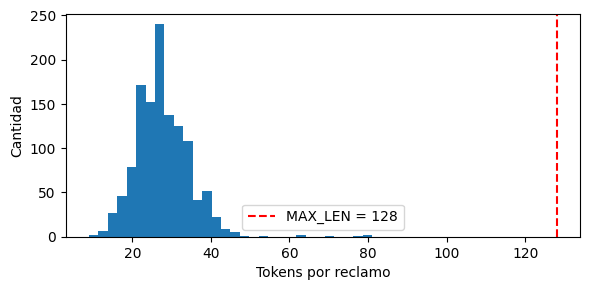

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

ejemplo = train.loc[0, "entrada"]
ids = tokenizer(ejemplo)["input_ids"]
print("Texto :", ejemplo)
print("Tokens:", tokenizer.convert_ids_to_tokens(ids))
print("IDs   :", ids)

largos = [len(tokenizer(t)["input_ids"]) for t in train["entrada"]]
print(f"\nLongitud en tokens: media={np.mean(largos):.1f}  p95={np.percentile(largos, 95):.0f}  máx={max(largos)}")

plt.figure(figsize=(6, 3))
plt.hist(largos, bins=30)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.xlabel("Tokens por reclamo"); plt.ylabel("Cantidad"); plt.legend()
plt.tight_layout(); plt.show()

## 8. Dataset y DataLoader

Empaquetamos los datos para alimentar la red por **lotes**, como en el notebook 02:

- `ReclamosDataset` tokeniza los textos una vez y entrega, por reclamo, sus tokens y **dos etiquetas** (`y_cat` e `y_grav`).
- `colatar` junta varios reclamos en un lote y rellena cada texto hasta el largo del más largo **del lote**; la `attention_mask` le dice al modelo qué posiciones son relleno.
- El `DataLoader` de entrenamiento **mezcla** los datos en cada época.

In [8]:
class ReclamosDataset(Dataset):
    def __init__(self, textos, y_cat, y_grav):
        self.enc = tokenizer(list(textos), truncation=True, max_length=MAX_LEN)
        self.yc = [int(v) for v in y_cat]
        self.yg = [int(v) for v in y_grav]

    def __len__(self):
        return len(self.yc)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["y_cat"] = self.yc[i]
        item["y_grav"] = self.yg[i]
        return item

def colatar(lote):
    y_c = torch.tensor([x["y_cat"] for x in lote], dtype=torch.long)
    y_g = torch.tensor([x["y_grav"] for x in lote], dtype=torch.long)
    feats = [{k: v for k, v in x.items() if k not in ("y_cat", "y_grav")} for x in lote]
    batch = tokenizer.pad(feats, return_tensors="pt")
    batch["y_cat"], batch["y_grav"] = y_c, y_g
    return batch

ds_train = ReclamosDataset(train["entrada"], train["y_cat"], train["y_grav"])
ds_val = ReclamosDataset(val["entrada"], val["y_cat"], val["y_grav"])
ds_test = ReclamosDataset(test["entrada"], test["y_cat"], test["y_grav"])

loader_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True, collate_fn=colatar)
loader_val = DataLoader(ds_val, batch_size=BATCH * 2, shuffle=False, collate_fn=colatar)
loader_test = DataLoader(ds_test, batch_size=BATCH * 2, shuffle=False, collate_fn=colatar)

print(f"Lotes por época -> train: {len(loader_train)} | val: {len(loader_val)} | test: {len(loader_test)}")

Lotes por época -> train: 77 | val: 2 | test: 2


## 9. El modelo multitarea

Es la idea del notebook 03 (BERT + capa encima) con **dos salidas**:

1. **BETO** convierte cada token en un vector que ya incluye el **contexto** de toda la frase gracias a la *self-attention* (la idea del notebook 05).
2. **Mean pooling:** promediamos los vectores de los tokens reales (ignorando el relleno) y obtenemos **un vector por reclamo**.
3. **Dropout:** apaga neuronas al azar al entrenar para reducir el sobreajuste.
4. **Dos cabezas lineales sobre el mismo vector:** `fc_cat` produce 8 números (uno por categoría) y `fc_grav` produce 3 (uno por gravedad). Son los *logits*.

Las dos tareas **comparten** BETO pero tienen **capas finales separadas**, así que cada una decide con su propio criterio.

In [9]:
class ClasificadorReclamos(nn.Module):
    def __init__(self, nombre, n_cat=8, n_grav=3, dropout=0.3, congelar_bert=False):
        super().__init__()
        self.bert = AutoModel.from_pretrained(nombre)
        self.drop = nn.Dropout(dropout)
        oculto = self.bert.config.hidden_size
        self.fc_cat = nn.Linear(oculto, n_cat)
        self.fc_grav = nn.Linear(oculto, n_grav)
        if congelar_bert:
            for p in self.bert.parameters():
                p.requires_grad = False

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        kwargs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids
        h = self.bert(**kwargs).last_hidden_state              # [lote, tokens, 768]
        mascara = attention_mask.unsqueeze(-1).float()         # 1 = token real, 0 = relleno
        pooled = self.drop((h * mascara).sum(1) / mascara.sum(1).clamp(min=1e-9))
        return self.fc_cat(pooled), self.fc_grav(pooled)       # (logits categoría, logits gravedad)

## 10. Pérdidas, optimizador y *scheduler*

Aquí se define **cómo aprende** la red (el descenso del gradiente):

- **Dos pérdidas** (`CrossEntropyLoss`), una por tarea, que se suman con los pesos `PESO_LOSS_CAT` y `PESO_LOSS_GRAV`. Con `ignore_index=-100`, los reclamos a los que les falta una etiqueta simplemente no cuentan para esa tarea. Con `USAR_PESOS_CLASE`, las clases con menos ejemplos pesan más.
- `perdida_tarea`: si en un lote **ninguno** tiene etiqueta para una tarea, devuelve 0 en vez de un valor inválido.
- **Optimizador `AdamW`:** calcula el gradiente y mueve los pesos en sentido contrario, con pasos de tamaño `LR`.
- **Scheduler lineal con *warmup*:** la tasa de aprendizaje sube suave al inicio y luego baja hasta cero.

In [10]:
modelo = ClasificadorReclamos(MODELO_BASE, n_cat=len(CATEGORIAS), n_grav=3, dropout=DROPOUT,
                              congelar_bert=CONGELAR_BERT).to(DEVICE)

def pesos_balanceados(y, n):
    y = np.array(y); y = y[y >= 0]
    if len(y) == 0:
        return np.ones(n)
    conteo = np.bincount(y, minlength=n)
    return len(y) / (n * np.maximum(conteo, 1))

w_cat = pesos_balanceados(train["y_cat"], len(CATEGORIAS)) if USAR_PESOS_CLASE else np.ones(len(CATEGORIAS))
w_grav = pesos_balanceados(train["y_grav"], 3) if USAR_PESOS_CLASE else np.ones(3)

criterio_cat = nn.CrossEntropyLoss(weight=torch.tensor(w_cat, dtype=torch.float).to(DEVICE), ignore_index=-100, label_smoothing=SUAVIZADO)
criterio_grav = nn.CrossEntropyLoss(weight=torch.tensor(w_grav, dtype=torch.float).to(DEVICE), ignore_index=-100, label_smoothing=SUAVIZADO)

def perdida_tarea(logits, y, criterio):
    if (y >= 0).any():
        return criterio(logits, y)
    return logits.sum() * 0.0

parametros = [p for p in modelo.parameters() if p.requires_grad]
optimizador = torch.optim.AdamW(parametros, lr=LR, weight_decay=WEIGHT_DECAY)
pasos_total = len(loader_train) * EPOCAS
scheduler = get_linear_schedule_with_warmup(optimizador, int(WARMUP * pasos_total), pasos_total)

print("Pesos categoría:", np.round(w_cat, 2))
print("Pesos gravedad :", np.round(w_grav, 2))
print(f"Parámetros entrenables: {sum(p.numel() for p in parametros):,} de {sum(p.numel() for p in modelo.parameters()):,}")

W1122 00:59:48.322000 18860 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pesos categoría: [1.01 1.   0.98 1.   1.   1.02 0.99 1.  ]
Pesos gravedad : [1.21 0.89 0.95]
Parámetros entrenables: 109,859,339 de 109,859,339


## 11. Funciones de entrenamiento y evaluación

Igual que las funciones `fit` de los notebooks 02 y 03, separamos dos tareas:

- **`entrenar_epoca`:** en cada lote hace el ciclo clásico: propagación hacia adelante → **pérdida total** (suma de las dos pérdidas) → `backward()` (gradientes) → **recorte del gradiente** (nos devuelve su norma antes de recortar) → `optimizer.step()`. Guarda la pérdida y la norma del gradiente **de cada paso**.
- **`evaluar`:** modo evaluación (sin dropout y sin gradientes). Devuelve, **para cada tarea**, la pérdida, el F1 macro, la exactitud, las predicciones, las etiquetas reales y las probabilidades.

La métrica principal de cada tarea es el **F1 macro** (promedio del F1 de todas las clases), que trata igual a las clases grandes y a las pequeñas. Solo se calcula con los reclamos que tienen etiqueta de esa tarea.

In [11]:
def puntajes(y, pred, n):
    m = y >= 0
    if m.sum() == 0:
        return float("nan"), float("nan")
    f1 = f1_score(y[m], pred[m], average="macro", labels=list(range(n)), zero_division=0)
    return f1, accuracy_score(y[m], pred[m])

def entrenar_epoca(modelo, loader, historial):
    modelo.train()
    suma, n = 0.0, 0
    for lote in loader:
        lote = {k: v.to(DEVICE) for k, v in lote.items()}
        y_c, y_g = lote.pop("y_cat"), lote.pop("y_grav")

        optimizador.zero_grad()
        logits_c, logits_g = modelo(**lote)
        perdida = (PESO_LOSS_CAT * perdida_tarea(logits_c, y_c, criterio_cat)
                   + PESO_LOSS_GRAV * perdida_tarea(logits_g, y_g, criterio_grav))
        perdida.backward()
        norma = torch.nn.utils.clip_grad_norm_(modelo.parameters(), MAX_GRAD_NORM)
        optimizador.step()
        scheduler.step()

        historial["loss_paso"].append(perdida.item())
        historial["grad_norm"].append(float(norma))
        suma += perdida.item() * len(y_c)
        n += len(y_c)
    return suma / n

@torch.no_grad()
def evaluar(modelo, loader):
    modelo.eval()
    sc = sg = 0.0; nc = ng = 0
    pc, pg, yc, yg, prc, prg = [], [], [], [], [], []
    for lote in loader:
        lote = {k: v.to(DEVICE) for k, v in lote.items()}
        y_c, y_g = lote.pop("y_cat"), lote.pop("y_grav")
        logits_c, logits_g = modelo(**lote)
        vc, vg = int((y_c >= 0).sum()), int((y_g >= 0).sum())
        if vc: sc += criterio_cat(logits_c, y_c).item() * vc; nc += vc
        if vg: sg += criterio_grav(logits_g, y_g).item() * vg; ng += vg
        p_c, p_g = torch.softmax(logits_c, -1), torch.softmax(logits_g, -1)
        prc.append(p_c.cpu().numpy()); prg.append(p_g.cpu().numpy())
        pc.extend(p_c.argmax(-1).cpu().tolist()); pg.extend(p_g.argmax(-1).cpu().tolist())
        yc.extend(y_c.cpu().tolist()); yg.extend(y_g.cpu().tolist())
    r = {"pred_cat": np.array(pc), "pred_grav": np.array(pg), "y_cat": np.array(yc), "y_grav": np.array(yg),
         "prob_cat": np.concatenate(prc), "prob_grav": np.concatenate(prg),
         "loss_cat": sc / nc if nc else 0.0, "loss_grav": sg / ng if ng else 0.0}
    r["loss"] = PESO_LOSS_CAT * r["loss_cat"] + PESO_LOSS_GRAV * r["loss_grav"]
    r["f1_cat"], r["acc_cat"] = puntajes(r["y_cat"], r["pred_cat"], len(CATEGORIAS))
    r["f1_grav"], r["acc_grav"] = puntajes(r["y_grav"], r["pred_grav"], 3)
    return r

## 12. Entrenamiento

Es el bucle principal. En cada **época** (una pasada completa por el entrenamiento):

1. Entrenamos y medimos la pérdida de entrenamiento.
2. Evaluamos en **validación**, para las dos tareas.
3. Calculamos un **puntaje combinado**: el promedio de los F1 macro de categoría y gravedad. Si el puntaje es el **mejor hasta ahora**, guardamos una copia de los pesos (nos quedamos con el mejor modelo, no con el último).
4. **Parada temprana:** si pasan `PACIENCIA` épocas sin mejorar, paramos para evitar el sobreajuste (lo que pasaba en el notebook 04, donde la pérdida de validación subía mientras la de entrenamiento bajaba).

Al final se cargan los pesos de la mejor época. Con GPU tarda unos minutos; en CPU puede tardar mucho más.

In [12]:
historial = {"loss_paso": [], "grad_norm": [], "loss_train": [], "loss_val": [], "loss_val_cat": [], "loss_val_grav": [],
             "f1_cat": [], "f1_grav": [], "acc_cat": [], "acc_grav": [], "score": []}
mejor_score, mejor_epoca, mejor_estado, sin_mejora = -1.0, 0, None, 0

for epoca in range(1, EPOCAS + 1):
    t0 = time.time()
    loss_tr = entrenar_epoca(modelo, loader_train, historial)
    rv = evaluar(modelo, loader_val)

    score = float(np.nanmean([rv["f1_cat"], rv["f1_grav"]]))
    if SCORE_GRAVEDAD and not np.isnan(rv["f1_grav"]):
        score = float(rv["f1_grav"])
    for k, v in [("loss_train", loss_tr), ("loss_val", rv["loss"]), ("loss_val_cat", rv["loss_cat"]),
                 ("loss_val_grav", rv["loss_grav"]), ("f1_cat", rv["f1_cat"]), ("f1_grav", rv["f1_grav"]),
                 ("acc_cat", rv["acc_cat"]), ("acc_grav", rv["acc_grav"]), ("score", score)]:
        historial[k].append(v)

    marca = ""
    if score > mejor_score:
        mejor_score, mejor_epoca, sin_mejora = score, epoca, 0
        mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        marca = "  <- mejor"
    else:
        sin_mejora += 1

    print(f"Época {epoca:02d}/{EPOCAS} | loss train {loss_tr:.3f} | loss val {rv['loss']:.3f} | "
          f"F1 cat {rv['f1_cat']:.3f} | F1 grav {rv['f1_grav']:.3f} | combinado {score:.3f} | {time.time() - t0:.0f}s{marca}")

    if sin_mejora >= PACIENCIA:
        print(f"Parada temprana: {PACIENCIA} épocas sin mejorar.")
        break

modelo.load_state_dict(mejor_estado)
print(f"\nMejor época: {mejor_epoca} (puntaje combinado en validación = {mejor_score:.4f})")

Época 01/20 | loss train 3.189 | loss val 3.060 | F1 cat 0.423 | F1 grav 0.180 | combinado 0.301 | 386s  <- mejor
Época 02/20 | loss train 2.104 | loss val 1.332 | F1 cat 0.898 | F1 grav 0.436 | combinado 0.667 | 376s  <- mejor
Época 03/20 | loss train 0.961 | loss val 1.066 | F1 cat 1.000 | F1 grav 0.438 | combinado 0.719 | 374s  <- mejor
Época 04/20 | loss train 0.653 | loss val 1.152 | F1 cat 1.000 | F1 grav 0.459 | combinado 0.729 | 374s  <- mejor
Época 05/20 | loss train 0.466 | loss val 1.209 | F1 cat 1.000 | F1 grav 0.501 | combinado 0.750 | 377s  <- mejor
Época 06/20 | loss train 0.338 | loss val 1.779 | F1 cat 1.000 | F1 grav 0.411 | combinado 0.706 | 388s
Época 07/20 | loss train 0.228 | loss val 2.250 | F1 cat 0.975 | F1 grav 0.375 | combinado 0.675 | 397s
Época 08/20 | loss train 0.155 | loss val 1.937 | F1 cat 0.975 | F1 grav 0.468 | combinado 0.721 | 389s
Época 09/20 | loss train 0.127 | loss val 1.990 | F1 cat 0.975 | F1 grav 0.426 | combinado 0.700 | 385s
Época 10/20 | 

## 13. Descenso del gradiente

Seis gráficos para ver **cómo aprendió** el modelo:

1. **Pérdida por paso:** cada punto es un lote; la línea gruesa es la media móvil. Debe bajar con ruido: es el descenso del gradiente.
2. **Pérdida total por época (train vs validación):** si ambas bajan juntas, aprende bien. Si la de entrenamiento baja y la de validación sube, hay **sobreajuste**. La línea vertical marca la época elegida.
3. **Pérdida de validación por tarea:** muestra si las dos tareas aprenden o si una se estanca.
4. **F1 macro de validación por tarea** y el combinado que decidió el mejor modelo.
5. **Exactitud de validación por tarea.**
6. **Norma del gradiente** por paso (escala logarítmica). Suele ser mayor al inicio y calmarse; si queda siempre por encima de la línea roja, el recorte actúa en todos los pasos (puedes subir `MAX_GRAD_NORM`).

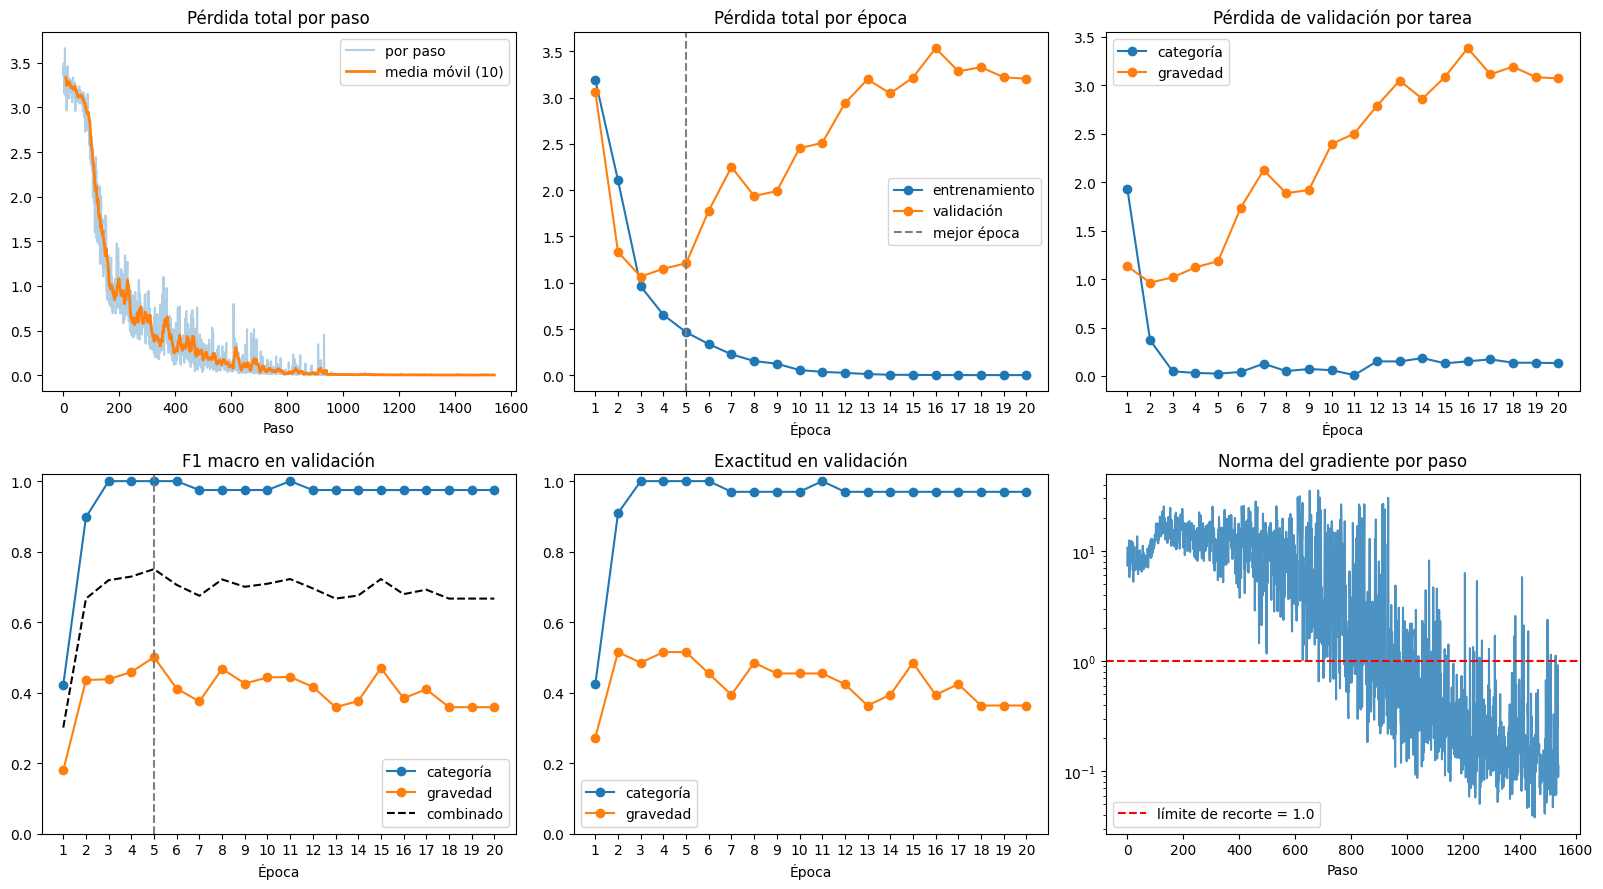

In [13]:
def media_movil(x, k):
    return np.convolve(x, np.ones(k) / k, mode="valid")

ep = list(range(1, len(historial["loss_train"]) + 1))
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

pasos = historial["loss_paso"]; k = min(10, len(pasos))
ax[0, 0].plot(pasos, alpha=0.35, label="por paso")
if len(pasos) >= k:
    ax[0, 0].plot(range(k - 1, len(pasos)), media_movil(pasos, k), linewidth=2, label=f"media móvil ({k})")
ax[0, 0].set_title("Pérdida total por paso"); ax[0, 0].set_xlabel("Paso"); ax[0, 0].legend()

ax[0, 1].plot(ep, historial["loss_train"], "o-", label="entrenamiento")
ax[0, 1].plot(ep, historial["loss_val"], "o-", label="validación")
ax[0, 1].axvline(mejor_epoca, color="gray", linestyle="--", label="mejor época")
ax[0, 1].set_title("Pérdida total por época"); ax[0, 1].set_xlabel("Época"); ax[0, 1].set_xticks(ep); ax[0, 1].legend()

ax[0, 2].plot(ep, historial["loss_val_cat"], "o-", label="categoría")
ax[0, 2].plot(ep, historial["loss_val_grav"], "o-", label="gravedad")
ax[0, 2].set_title("Pérdida de validación por tarea"); ax[0, 2].set_xlabel("Época"); ax[0, 2].set_xticks(ep); ax[0, 2].legend()

ax[1, 0].plot(ep, historial["f1_cat"], "o-", label="categoría")
ax[1, 0].plot(ep, historial["f1_grav"], "o-", label="gravedad")
ax[1, 0].plot(ep, historial["score"], "k--", label="combinado")
ax[1, 0].axvline(mejor_epoca, color="gray", linestyle="--")
ax[1, 0].set_ylim(0, 1.02); ax[1, 0].set_title("F1 macro en validación"); ax[1, 0].set_xlabel("Época")
ax[1, 0].set_xticks(ep); ax[1, 0].legend()

ax[1, 1].plot(ep, historial["acc_cat"], "o-", label="categoría")
ax[1, 1].plot(ep, historial["acc_grav"], "o-", label="gravedad")
ax[1, 1].set_ylim(0, 1.02); ax[1, 1].set_title("Exactitud en validación"); ax[1, 1].set_xlabel("Época")
ax[1, 1].set_xticks(ep); ax[1, 1].legend()

ax[1, 2].semilogy(historial["grad_norm"], alpha=0.8)
ax[1, 2].axhline(MAX_GRAD_NORM, color="red", linestyle="--", label=f"límite de recorte = {MAX_GRAD_NORM}")
ax[1, 2].set_title("Norma del gradiente por paso"); ax[1, 2].set_xlabel("Paso"); ax[1, 2].legend()

plt.tight_layout(); plt.show()

## 14. Métricas en el conjunto de prueba

Ahora usamos la **prueba**, que el modelo nunca vio. Para **cada tarea** calculamos:

- **Exactitud (accuracy):** porcentaje de aciertos; engaña si las clases están desbalanceadas.
- **F1 macro:** promedio del F1 de cada clase; la métrica principal. El F1 combina *precisión* (de lo que dije que era X, cuánto lo era) y *recall* (de lo realmente X, cuánto detecté).
- **F1 ponderado:** igual, pero pesando por cantidad de ejemplos.
- **Línea base:** el F1 que sacaría un "modelo" que siempre responde la clase más común. Debemos superarla con claridad.
- **Reporte por clase:** precisión, recall y F1 de cada categoría y de cada gravedad.
- Solo para gravedad: el **kappa cuadrático ponderado**, que penaliza más los errores lejanos (confundir leve con grave pesa más que moderada con grave).

In [14]:
res_test = evaluar(modelo, loader_test)
print(f"Modo de evaluación: {modo}\n")

# ---------------- GRAVEDAD ----------------
mg = res_test["y_grav"] >= 0
yg, pg = res_test["y_grav"][mg], res_test["pred_grav"][mg]
may_g = int(np.bincount(train.loc[train["y_grav"] >= 0, "y_grav"], minlength=3).argmax())
print("=" * 60); print("GRAVEDAD"); print("=" * 60)
if mg.sum():
    print(f"Exactitud                 : {accuracy_score(yg, pg):.4f}")
    print(f"F1 macro                  : {f1_score(yg, pg, average='macro', labels=[0, 1, 2], zero_division=0):.4f}")
    print(f"F1 ponderado              : {f1_score(yg, pg, average='weighted', labels=[0, 1, 2], zero_division=0):.4f}")
    print(f"Kappa cuadrático ponderado: {cohen_kappa_score(yg, pg, weights='quadratic'):.4f}")
    print(f"Línea base (siempre clase {may_g}) -> F1 macro: "
          f"{f1_score(yg, [may_g] * len(yg), average='macro', labels=[0, 1, 2], zero_division=0):.4f}\n")
    print(classification_report(yg, pg, labels=[0, 1, 2], target_names=NOMBRES_GRAV, digits=3, zero_division=0))
else:
    print("No hay reclamos con gravedad en el conjunto de prueba.")

# ---------------- CATEGORÍA ----------------
mc = res_test["y_cat"] >= 0
yc, pc = res_test["y_cat"][mc], res_test["pred_cat"][mc]
may_c = int(np.bincount(train.loc[train["y_cat"] >= 0, "y_cat"], minlength=len(CATEGORIAS)).argmax())
print("=" * 60); print("CATEGORÍA"); print("=" * 60)
if mc.sum():
    etiquetas_c = list(range(len(CATEGORIAS)))
    print(f"Exactitud     : {accuracy_score(yc, pc):.4f}")
    print(f"F1 macro      : {f1_score(yc, pc, average='macro', labels=etiquetas_c, zero_division=0):.4f}")
    print(f"F1 ponderado  : {f1_score(yc, pc, average='weighted', labels=etiquetas_c, zero_division=0):.4f}")
    print(f"Línea base (siempre '{CATEGORIAS[may_c]}') -> F1 macro: "
          f"{f1_score(yc, [may_c] * len(yc), average='macro', labels=etiquetas_c, zero_division=0):.4f}\n")
    print(classification_report(yc, pc, labels=etiquetas_c, target_names=CATEGORIAS, digits=3, zero_division=0))
else:
    print("No hay reclamos con categoría en el conjunto de prueba.")

f1_grav_test = float(res_test["f1_grav"]); f1_cat_test = float(res_test["f1_cat"])

Modo de evaluación: val y test SOLO con reclamos reales (recomendado)

GRAVEDAD
Exactitud                 : 0.5789
F1 macro                  : 0.5794
F1 ponderado              : 0.5835
Kappa cuadrático ponderado: 0.4388
Línea base (siempre clase 1) -> F1 macro: 0.1732

              precision    recall  f1-score   support

    0 · Leve      0.846     0.478     0.611        23
1 · Moderada      0.545     0.600     0.571        20
   2 · Grave      0.455     0.714     0.556        14

    accuracy                          0.579        57
   macro avg      0.615     0.598     0.579        57
weighted avg      0.644     0.579     0.584        57

CATEGORÍA
Exactitud     : 1.0000
F1 macro      : 1.0000
F1 ponderado  : 1.0000
Línea base (siempre 'Alumbrado público') -> F1 macro: 0.0202

                         precision    recall  f1-score   support

       Recojo de basura      1.000     1.000     1.000         9
  Agua y alcantarillado      1.000     1.000     1.000         6
      Alumbr

## 15. Matrices de confusión

Cada fila es la clase **real** y cada columna la **predicha**. La diagonal son los aciertos; fuera de ella están los errores y se ve **cuáles**.

- **Gravedad** (3×3): lo más costoso es la celda *real = Grave, predicho = Leve*, un riesgo serio que el sistema subestimaría.
- **Categoría** (8×8, a la derecha en porcentaje por fila): muestra qué categorías se confunden entre sí. Es la clave para el verificador: si dos categorías se confunden mucho, el modelo dudará justo ahí.

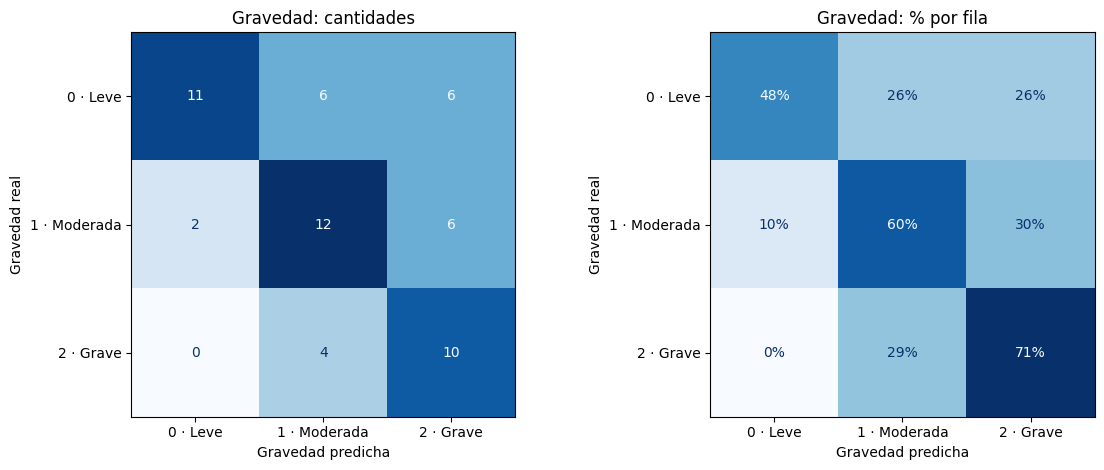

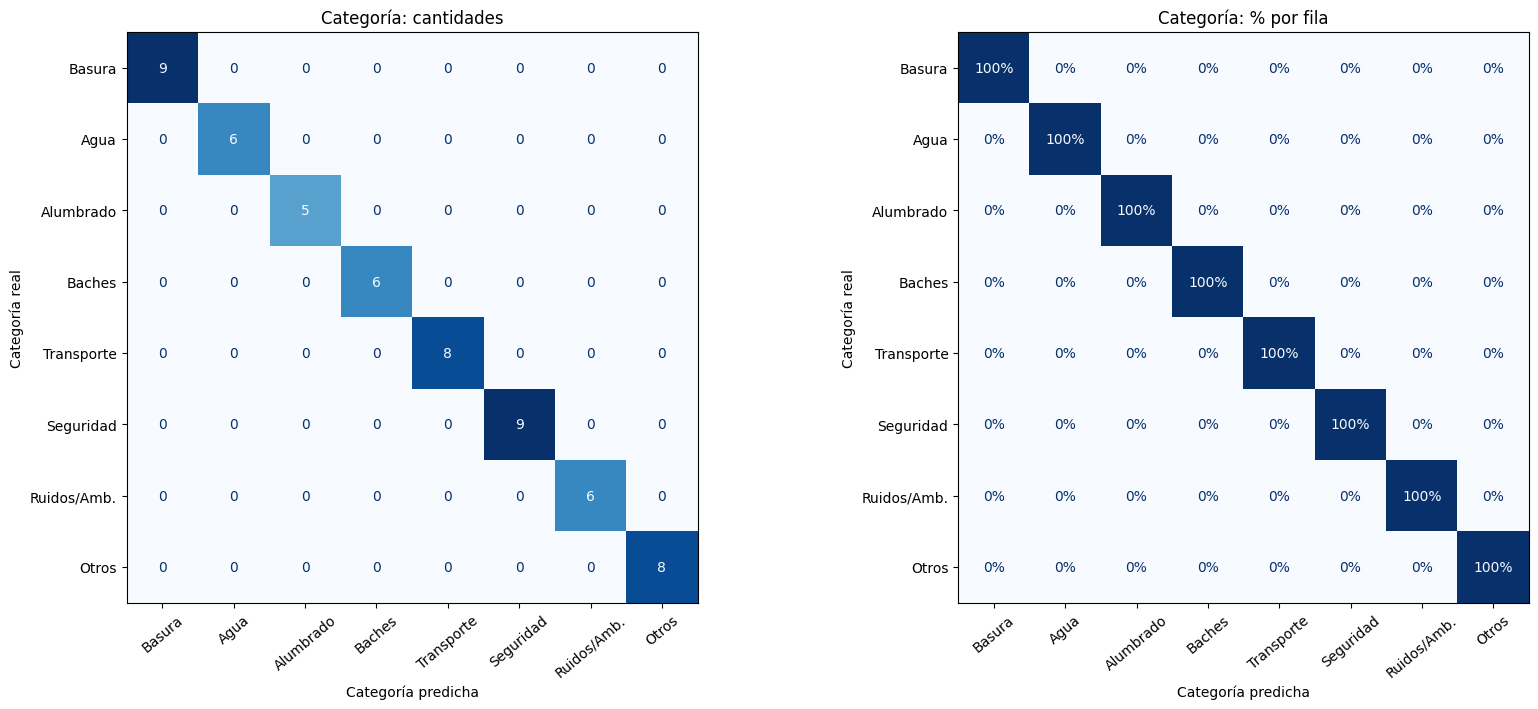

In [15]:
if mg.sum():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
    ConfusionMatrixDisplay.from_predictions(yg, pg, labels=[0, 1, 2], display_labels=NOMBRES_GRAV, cmap="Blues", ax=ax[0], colorbar=False)
    ax[0].set_title("Gravedad: cantidades")
    ConfusionMatrixDisplay.from_predictions(yg, pg, labels=[0, 1, 2], display_labels=NOMBRES_GRAV, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax[1], colorbar=False)
    ax[1].set_title("Gravedad: % por fila")
    for a in ax: a.set_xlabel("Gravedad predicha"); a.set_ylabel("Gravedad real")
    plt.tight_layout(); plt.show()

if mc.sum():
    fig, ax = plt.subplots(1, 2, figsize=(17, 7.2))
    ConfusionMatrixDisplay.from_predictions(yc, pc, labels=list(range(len(CATEGORIAS))), display_labels=CAT_CORTO,
                                            cmap="Blues", ax=ax[0], colorbar=False, xticks_rotation=40)
    ax[0].set_title("Categoría: cantidades")
    ConfusionMatrixDisplay.from_predictions(yc, pc, labels=list(range(len(CATEGORIAS))), display_labels=CAT_CORTO,
                                            normalize="true", values_format=".0%", cmap="Blues", ax=ax[1],
                                            colorbar=False, xticks_rotation=40)
    ax[1].set_title("Categoría: % por fila")
    for a in ax: a.set_xlabel("Categoría predicha"); a.set_ylabel("Categoría real")
    plt.tight_layout(); plt.show()

## 16. Análisis por riesgo, por categoría y en casos difíciles

Las métricas globales esconden detalles importantes:

- **Errores por riesgo (gravedad):** qué porcentaje de los realmente graves se **subestima**, cuántos se marcan **leves** (el error más peligroso) y cuántos leves se **sobreestiman** (falsas alarmas).
- **Rendimiento por categoría:** exactitud de la categoría y de la gravedad para cada categoría real.
- **Pares de categorías más confundidos:** qué categorías el modelo mezcla más.
- **Casos difíciles** (`caso_dificil = Sí`: tono alarmista con problema leve, o tono calmado con problema grave). Si aquí rinde mucho peor, el modelo se guía por palabras sueltas y no por el contexto.

In [16]:
res = test.copy()
for k in ("pred_cat", "pred_grav"):
    res[k] = res_test[k]
res["conf_cat"] = res_test["prob_cat"].max(axis=1)
res["conf_grav"] = res_test["prob_grav"].max(axis=1)
res["ok_cat"] = np.where(res["y_cat"] >= 0, res["pred_cat"] == res["y_cat"], np.nan)
res["ok_grav"] = np.where(res["y_grav"] >= 0, res["pred_grav"] == res["y_grav"], np.nan)

g = res[res["y_grav"] >= 0]
graves, leves = g[g["y_grav"] == 2], g[g["y_grav"] == 0]
if len(graves):
    print(f"Graves subestimados (marcados 0 o 1): {(graves['pred_grav'] < 2).mean():.1%}  de {len(graves)}")
    print(f"Graves marcados como LEVES (error crítico): {(graves['pred_grav'] == 0).mean():.1%}")
if len(leves):
    print(f"Leves sobreestimados (marcados 1 o 2): {(leves['pred_grav'] > 0).mean():.1%}  de {len(leves)}")

print("\nRendimiento por categoría real (test):")
por_cat = res[res["categoria"].notna()].groupby("categoria").agg(
    n=("texto", "size"), exactitud_categoria=("ok_cat", "mean"), exactitud_gravedad=("ok_grav", "mean")).round(3)
display(por_cat)

if mc.sum():
    cm = confusion_matrix(yc, pc, labels=list(range(len(CATEGORIAS))))
    pares = [(CATEGORIAS[i], CATEGORIAS[j], int(cm[i, j])) for i in range(len(CATEGORIAS))
             for j in range(len(CATEGORIAS)) if i != j and cm[i, j] > 0]
    pares = sorted(pares, key=lambda x: -x[2])[:8]
    print("Categorías más confundidas (real -> predicha):")
    display(pd.DataFrame(pares, columns=["real", "predicha", "veces"]) if pares else pd.DataFrame({"resultado": ["Sin confusiones"]}))

print("Casos difíciles vs. normales (exactitud de gravedad):")
tabla_dif = g.groupby("caso_dificil").agg(n=("texto", "size"), exactitud=("ok_grav", "mean")).round(3)
display(tabla_dif)
if "Sí" not in tabla_dif.index:
    print("(No hay casos difíciles en el conjunto de prueba.)")

Graves subestimados (marcados 0 o 1): 28.6%  de 14
Graves marcados como LEVES (error crítico): 0.0%
Leves sobreestimados (marcados 1 o 2): 52.2%  de 23

Rendimiento por categoría real (test):


,n,exactitud_categoria,exactitud_gravedad
categoria,,,
Agua y alcantarillado,6,1.0,0.000
Alumbrado público,5,1.0,0.800
Baches y vías,6,1.0,1.000
Otros,8,1.0,1.000
Recojo de basura,9,1.0,0.222
Ruidos y medio ambiente,6,1.0,0.667
Seguridad ciudadana,9,1.0,0.667
Transporte y tránsito,8,1.0,0.375


Categorías más confundidas (real -> predicha):


,resultado
0,Sin confusiones


Casos difíciles vs. normales (exactitud de gravedad):


,n,exactitud
caso_dificil,,
No,57,0.579


(No hay casos difíciles en el conjunto de prueba.)


## 16b. Umbral de gravedad: no pasar por alto un caso grave

Por defecto el modelo elige la gravedad **más probable**. Pero en este sistema **no detectar un caso grave cuesta mucho más que una falsa alarma**. Lo corregimos con un **umbral**: si la probabilidad de *grave* supera un valor (menor que 0,5), el reclamo se marca **grave** aunque otra clase tenga más probabilidad.

Se calibra con la **validación**: probamos varios umbrales y elegimos el **más alto** que alcanza `RECALL_GRAVE_OBJETIVO` (qué fracción de los realmente graves se detecta), que es el que genera menos falsas alarmas. Después mostramos cómo queda en la **prueba**, comparado con elegir la clase más probable.

**Costo:** al ser más sensible, más reclamos no graves se marcarán graves. La tabla lo muestra. Con pocos reclamos graves en la validación el umbral es aproximado.

In [17]:
RECALL_GRAVE_OBJETIVO = 0.85

def recall_precision_grave(res, umbral):
    m = res["y_grav"] >= 0
    y = res["y_grav"][m] == 2
    pred = res["prob_grav"][m][:, 2] >= umbral
    tp = int((y & pred).sum())
    rec = tp / y.sum() if y.sum() else float("nan")
    prec = tp / pred.sum() if pred.sum() else float("nan")
    return rec, prec, int((~y & pred).sum())

res_val_g = evaluar(modelo, loader_val)
filas_g = []
for u in np.round(np.arange(0.10, 0.65, 0.05), 2):
    rec, prec, falsas = recall_precision_grave(res_val_g, u)
    filas_g.append({"umbral_grave": u, "recall_graves": round(rec, 3), "precision": round(prec, 3), "falsas_alarmas": falsas})
tabla_g = pd.DataFrame(filas_g, columns=["umbral_grave", "recall_graves", "precision", "falsas_alarmas"])
valid = tabla_g.dropna(subset=["recall_graves"])
if len(valid):
    ok = valid[valid["recall_graves"] >= RECALL_GRAVE_OBJETIVO]
    mejor = valid[valid["recall_graves"] == valid["recall_graves"].max()]
    UMBRAL_GRAVE = float(ok["umbral_grave"].max()) if len(ok) else float(mejor["umbral_grave"].max())
else:
    UMBRAL_GRAVE = 0.35
display(tabla_g)
print(f"Umbral de gravedad elegido: {UMBRAL_GRAVE:.2f}")

mt = res_test["y_grav"] >= 0
if mt.sum():
    yt = res_test["y_grav"][mt]
    p_arg = res_test["pred_grav"][mt]
    p_umb = np.where(res_test["prob_grav"][mt][:, 2] >= UMBRAL_GRAVE, 2, p_arg)
    def resumen_g(pred):
        g = yt == 2
        return {"exactitud": round(float((pred == yt).mean()), 3),
                "F1 macro": round(float(f1_score(yt, pred, average="macro", labels=[0, 1, 2], zero_division=0)), 3),
                "graves detectados": f"{int((pred[g] == 2).sum())}/{int(g.sum())}",
                "no graves marcados graves": int(((pred == 2) & ~g).sum())}
    print("\nEfecto en la PRUEBA:")
    display(pd.DataFrame({"clase más probable": resumen_g(p_arg), f"con umbral {UMBRAL_GRAVE:.2f}": resumen_g(p_umb)}))

,umbral_grave,recall_graves,precision,falsas_alarmas
0,0.10,0.889,0.400,12
1,0.15,0.667,0.375,10
2,0.20,0.667,0.400,9
3,0.25,0.444,0.308,9
4,0.30,0.444,0.308,9
5,0.35,0.333,0.300,7
6,0.40,0.333,0.375,5
7,0.45,0.333,0.375,5
8,0.50,0.333,0.429,4
9,0.55,0.333,0.429,4


Umbral de gravedad elegido: 0.10

Efecto en la PRUEBA:


,clase más probable,con umbral 0.10
exactitud,0.579,0.526
F1 macro,0.579,0.527
graves detectados,10/14,11/14
no graves marcados graves,12,18


## 17. Umbral de confianza para decir "el ciudadano se equivocó"

El modelo no solo dice una categoría: también da **qué tan seguro está** (la probabilidad más alta). Para no acusar de error al ciudadano sin motivo, solo lo hacemos cuando la confianza del modelo supera un **umbral**.

Lo calibramos con la **validación** (no con la prueba):

1. Para cada umbral probamos: ¿en cuántos reclamos el modelo supera esa confianza (*cobertura*) y cuánto acierta en ellos (*exactitud*)?
2. Elegimos el **umbral más bajo** en el que la exactitud alcanza `PRECISION_OBJETIVO`, con al menos 10 casos y nunca por debajo de `UMBRAL_MIN_CAT`.

Subir el umbral hace que el modelo corrija menos, pero con más seguridad. Si la validación es pequeña, el umbral es aproximado.

También definimos aquí `veredicto_categoria`, la regla que compara la categoría del ciudadano con la del modelo.

,umbral,cobertura,exactitud,n
0,0.20,1.000,1.0,33
1,0.25,1.000,1.0,33
2,0.30,1.000,1.0,33
3,0.35,1.000,1.0,33
4,0.40,1.000,1.0,33
5,0.45,1.000,1.0,33
6,0.50,1.000,1.0,33
7,0.55,1.000,1.0,33
8,0.60,1.000,1.0,33
9,0.65,1.000,1.0,33


Umbral elegido: 0.60


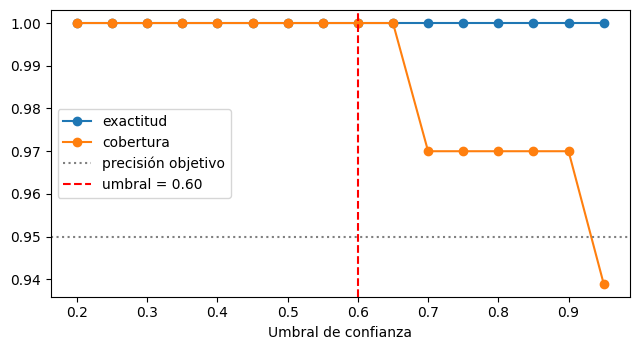

In [18]:
def veredicto_categoria(cat_ciudadano, pred, conf, umbral):
    # cat_ciudadano: índice 0..7, o None / negativo si el ciudadano no eligió categoría
    if cat_ciudadano is None or cat_ciudadano < 0:
        return "sin categoría"
    if pred == cat_ciudadano:
        return "coincide"
    return "posible error" if conf >= umbral else "dudosa"

rv = evaluar(modelo, loader_val)
m = rv["y_cat"] >= 0
conf_v = rv["prob_cat"].max(axis=1)[m]; pred_v = rv["pred_cat"][m]; y_v = rv["y_cat"][m]

filas = []
for u in np.round(np.arange(0.20, 0.99, 0.05), 2):
    sel = conf_v >= u
    if sel.sum() == 0:
        break
    filas.append({"umbral": u, "cobertura": round(float(sel.mean()), 3),
                  "exactitud": round(float((pred_v[sel] == y_v[sel]).mean()), 3), "n": int(sel.sum())})
tabla_u = pd.DataFrame(filas, columns=["umbral", "cobertura", "exactitud", "n"])
cand = tabla_u[(tabla_u["exactitud"] >= PRECISION_OBJETIVO) & (tabla_u["n"] >= 10) & (tabla_u["umbral"] >= UMBRAL_MIN_CAT)]
UMBRAL_CAT = float(cand["umbral"].min()) if len(cand) else 0.80
display(tabla_u)
print(f"Umbral elegido: {UMBRAL_CAT:.2f}" + ("" if len(cand) else "  (no se alcanzó la precisión objetivo; se usó el valor por defecto 0.80)"))

if len(tabla_u):
    plt.figure(figsize=(6.5, 3.6))
    plt.plot(tabla_u["umbral"], tabla_u["exactitud"], "o-", label="exactitud")
    plt.plot(tabla_u["umbral"], tabla_u["cobertura"], "o-", label="cobertura")
    plt.axhline(PRECISION_OBJETIVO, color="gray", linestyle=":", label="precisión objetivo")
    plt.axvline(UMBRAL_CAT, color="red", linestyle="--", label=f"umbral = {UMBRAL_CAT:.2f}")
    plt.xlabel("Umbral de confianza"); plt.legend(); plt.tight_layout(); plt.show()
else:
    print("El modelo no alcanzó ninguna confianza evaluable; entrena más o revisa los datos.")

## 18. Simulación de errores del ciudadano

¿Cómo sabemos si el verificador funciona? No tenemos todavía reclamos reales con la categoría mal elegida, así que **simulamos**: en la prueba, cambiamos al azar la categoría de un `FRAC_ERROR_SIM` de los reclamos por otra equivocada, como si el ciudadano se hubiera equivocado, y vemos qué hace el verificador.

Medimos, sobre los **errores simulados**: cuántos detecta como *posible error* **y** sugiere la categoría correcta, cuántos manda a revisión (*dudosa*) y cuántos se le pasan (*coincide*). Y sobre los **reclamos bien categorizados**: cuántas **falsas alarmas** genera.

**Cuidado al interpretar:** los errores simulados son al azar, y los errores reales suelen ser más difíciles (alguien que elige *Alumbrado* para un problema de *Seguridad*). Estos números son un **máximo optimista**; los reales saldrán cuando recolectes reclamos con categorías mal elegidas.

In [19]:
rng = np.random.default_rng(SEMILLA)
mc_ = res_test["y_cat"] >= 0
y_c = res_test["y_cat"][mc_]; p_c = res_test["pred_cat"][mc_]; conf_c = res_test["prob_cat"].max(axis=1)[mc_]

es_error = rng.random(len(y_c)) < FRAC_ERROR_SIM
ciud = y_c.copy()
for i in np.where(es_error)[0]:
    ciud[i] = rng.choice([k for k in range(len(CATEGORIAS)) if k != y_c[i]])

veredictos = np.array([veredicto_categoria(a, b, c, UMBRAL_CAT) for a, b, c in zip(ciud, p_c, conf_c)])

print(f"Reclamos evaluados: {len(y_c)} | errores simulados: {es_error.sum()} | umbral: {UMBRAL_CAT:.2f}\n")
if es_error.sum():
    v_err = veredictos[es_error]
    detectado_ok = ((veredictos == "posible error") & (p_c == y_c) & es_error).sum()
    print("Sobre los errores simulados:")
    print(f"  Detectados como 'posible error' CON la categoría correcta sugerida: {detectado_ok} ({detectado_ok / es_error.sum():.1%})")
    print(f"  Enviados a revisión ('dudosa')                                    : {(v_err == 'dudosa').sum()} ({(v_err == 'dudosa').mean():.1%})")
    print(f"  Se le pasaron ('coincide')                                        : {(v_err == 'coincide').sum()} ({(v_err == 'coincide').mean():.1%})")
if (~es_error).sum():
    v_ok = veredictos[~es_error]
    print("\nSobre los reclamos bien categorizados:")
    print(f"  Corroborados ('coincide')                       : {(v_ok == 'coincide').mean():.1%}")
    print(f"  Falsas alarmas ('posible error')                : {(v_ok == 'posible error').sum()} ({(v_ok == 'posible error').mean():.1%})")
    print(f"  Enviados a revisión sin necesidad ('dudosa')    : {(v_ok == 'dudosa').sum()} ({(v_ok == 'dudosa').mean():.1%})")

Reclamos evaluados: 57 | errores simulados: 7 | umbral: 0.60

Sobre los errores simulados:
  Detectados como 'posible error' CON la categoría correcta sugerida: 7 (100.0%)
  Enviados a revisión ('dudosa')                                    : 0 (0.0%)
  Se le pasaron ('coincide')                                        : 0 (0.0%)

Sobre los reclamos bien categorizados:
  Corroborados ('coincide')                       : 100.0%
  Falsas alarmas ('posible error')                : 0 (0.0%)
  Enviados a revisión sin necesidad ('dudosa')    : 0 (0.0%)


## 19. Errores del modelo

Mirar los errores uno por uno enseña más que cualquier número. Mostramos los **10 errores con mayor confianza** de cada tarea: reclamos que el modelo clasificó mal estando muy seguro. Para cada uno pregúntate:

- ¿Se equivocó el modelo, o **la etiqueta humana es discutible**? En categorías es muy común: un reclamo como *«poste caído y robos»* encaja en dos. Si es discutible, el límite está en los datos.
- ¿Hay un patrón (mayúsculas, sarcasmo, gravedad implícita, problemas que mezclan categorías)? Eso te dice qué ejemplos agregar.

In [20]:
nombre_cat = dict(enumerate(CATEGORIAS))

e_cat = (res[(res["ok_cat"] == 0)].sort_values("conf_cat", ascending=False).head(10).copy())
e_cat["real"] = e_cat["y_cat"].map(nombre_cat); e_cat["predicha"] = e_cat["pred_cat"].map(nombre_cat)
print(f"ERRORES DE CATEGORÍA: {(res['ok_cat'] == 0).sum()} de {(res['y_cat'] >= 0).sum()}")
with pd.option_context("display.max_colwidth", 110, "display.width", 220):
    display(e_cat[["texto", "real", "predicha", "conf_cat"]].round(3))

e_grav = (res[(res["ok_grav"] == 0)].sort_values("conf_grav", ascending=False).head(10)
          [["texto", "y_grav", "pred_grav", "conf_grav"]].rename(columns={"y_grav": "real", "pred_grav": "predicha"}))
print(f"\nERRORES DE GRAVEDAD: {(res['ok_grav'] == 0).sum()} de {(res['y_grav'] >= 0).sum()}")
with pd.option_context("display.max_colwidth", 110, "display.width", 220):
    display(e_grav.round(3))

ERRORES DE CATEGORÍA: 0 de 57


,texto,real,predicha,conf_cat



ERRORES DE GRAVEDAD: 24 de 57


,texto,real,predicha,conf_grav
19,Hay un charco grande que nunca se seca y hay moscas y roedores y varios niños tuvieron fiebre.,1,2,0.964
47,Reclamo: asaltaron a una vecina en la esquina anoche. Esperamos una solución pronto.,1,2,0.957
45,Reclamo: cobran más de lo permitido en el micro desde hace cuatro días y nadie controla y los estudiantes ...,0,1,0.956
50,Vecinos de la zona: se prendió fuego un cable en el poste hace dos días y casi se incendia una casa cercan...,1,2,0.950
12,"Buenas tardes, un matadero tira desechos al arroyo desde hace diez días y murieron peces.",1,2,0.923
39,Reporto que los restos de verduras quedan tirados en la calle al final del día desde hace diez días y el m...,2,1,0.919
53,"Buenas tardes, la alcantarilla de la esquina está tapada desde hace meses y entra a los patios de las casas.",0,2,0.916
18,"buenas noches, el semáforo de la esquina no funciona desde hace casi un año y hay mucho tráfico en hora pico.",2,1,0.906
37,Reclamo: hay un botadero clandestino al final de la calle y hay niños jugando entre los desechos.,0,2,0.892
5,Vecinos de la zona: EMAS no recoge la basura en nuestro pasaje desde hace tres días y los perros rompen la...,1,2,0.877


## 20. Inferencia: analizar reclamos nuevos

Esta es la función que usará la página de administración. Recibe los textos y, **si se conoce, la categoría que eligió el ciudadano**, y devuelve para cada reclamo:

- **Categoría del modelo**, su probabilidad y una **segunda opción** (útil cuando el reclamo mezcla dos temas).
- **Veredicto:** `coincide`, `posible error`, `dudosa` o `sin categoría` (sección 17).
- **Categoría final**, que es la que usará el mapa de esa categoría:
  - *coincide* → la del ciudadano;
  - *posible error* → la del modelo si `AUTOCORREGIR = True` (si no, la del ciudadano);
  - *dudosa* → la del ciudadano, marcada para revisión manual;
  - *sin categoría* → la del modelo si supera el umbral; si no, queda vacía y en revisión.
- `requiere_revision`: `True` cuando una persona debería mirarlo.
- **Gravedad:** probabilidades, gravedad predicha (usa el umbral de la sección 16b) y una **gravedad continua** entre 0 y 1 (`0.5 × P(moderada) + 1.0 × P(grave)`), que se combina después con el peso de la categoría y el tamaño del grupo para pintar la zona.

Probamos con frases nuevas, algunas con la categoría **a propósito equivocada**.

In [21]:
@torch.no_grad()
def analizar(textos, categorias_ciudadano=None, modelo_=None, tok_=None, umbral=None, autocorregir=None):
    modelo_ = modelo_ or modelo
    tok_ = tok_ or tokenizer
    umbral = UMBRAL_CAT if umbral is None else umbral
    autocorregir = AUTOCORREGIR if autocorregir is None else autocorregir
    if isinstance(textos, str):
        textos = [textos]
    if categorias_ciudadano is None or isinstance(categorias_ciudadano, str):
        categorias_ciudadano = [categorias_ciudadano] * len(textos)

    modelo_.eval()
    enc = tok_(list(textos), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    lc, lg = modelo_(**enc)
    pc, pg = torch.softmax(lc, -1).cpu().numpy(), torch.softmax(lg, -1).cpu().numpy()

    filas = []
    for i, t in enumerate(textos):
        orden = np.argsort(-pc[i])
        mejor, segunda = int(orden[0]), int(orden[1])
        conf = float(pc[i, mejor])
        ciud_txt = categorias_ciudadano[i]
        ciud = IDX_CAT.get(CAT_MAP.get(str(ciud_txt).strip().lower())) if ciud_txt else None
        v = veredicto_categoria(ciud, mejor, conf, umbral)

        if v == "coincide":
            final, revisar = CATEGORIAS[ciud], False
        elif v == "posible error":
            final, revisar = (CATEGORIAS[mejor] if autocorregir else CATEGORIAS[ciud]), False
        elif v == "dudosa":
            final, revisar = CATEGORIAS[ciud], True
        else:   # sin categoría del ciudadano
            final, revisar = (CATEGORIAS[mejor], False) if conf >= umbral else ("", True)

        filas.append({
            "texto": t,
            "categoria_ciudadano": CATEGORIAS[ciud] if ciud is not None else "",
            "categoria_modelo": CATEGORIAS[mejor], "p_categoria": round(conf, 3),
            "segunda_opcion": CATEGORIAS[segunda], "p_segunda": round(float(pc[i, segunda]), 3),
            "veredicto_categoria": v, "categoria_final": final, "requiere_revision": revisar,
            "p_leve": round(float(pg[i, 0]), 3), "p_moderada": round(float(pg[i, 1]), 3), "p_grave": round(float(pg[i, 2]), 3),
            "gravedad_pred": 2 if pg[i, 2] >= UMBRAL_GRAVE else int(pg[i].argmax()),
            "gravedad_continua": round(float(pg[i, 1] * 0.5 + pg[i, 2]), 3),
        })
    return pd.DataFrame(filas)

casos = [
    ("Un cable de luz está caído en la vereda frente a la escuela y echa chispas.", "Alumbrado público"),
    ("Un cable de luz está caído en la vereda frente a la escuela y echa chispas.", "Seguridad ciudadana"),   # categoría equivocada a propósito
    ("Hace una semana no pasa el camión de basura por mi calle y huele mal.", "Recojo de basura"),
    ("El semáforo de la avenida no funciona y ya hubo un choque.", "Baches y vías"),                           # categoría equivocada a propósito
    ("No hay agua desde hace diez días y tengo un bebé en casa.", "Agua y alcantarillado"),
    ("URGENTE!!! una bolsa de basura en la esquina!!!", "Recojo de basura"),
    ("Hay un problema en mi calle", None),                                                                       # sin categoría y texto vago
]
nuevos = [c[0] for c in casos]; cats_ciud = [c[1] for c in casos]
with pd.option_context("display.max_colwidth", 60, "display.width", 250, "display.max_columns", 20):
    display(analizar(nuevos, cats_ciud)[["texto", "categoria_ciudadano", "categoria_modelo", "p_categoria", "veredicto_categoria",
                                         "categoria_final", "requiere_revision", "gravedad_pred", "gravedad_continua"]])

,texto,categoria_ciudadano,categoria_modelo,p_categoria,veredicto_categoria,categoria_final,requiere_revision,gravedad_pred,gravedad_continua
0,Un cable de luz está caído en la vereda frente a la escu...,Alumbrado público,Alumbrado público,0.969,coincide,Alumbrado público,False,2,0.995
1,Un cable de luz está caído en la vereda frente a la escu...,Seguridad ciudadana,Alumbrado público,0.969,posible error,Alumbrado público,False,2,0.995
2,Hace una semana no pasa el camión de basura por mi calle...,Recojo de basura,Recojo de basura,0.996,coincide,Recojo de basura,False,1,0.471
3,El semáforo de la avenida no funciona y ya hubo un choque.,Baches y vías,Transporte y tránsito,0.996,posible error,Transporte y tránsito,False,2,0.766
4,No hay agua desde hace diez días y tengo un bebé en casa.,Agua y alcantarillado,Agua y alcantarillado,0.995,coincide,Agua y alcantarillado,False,2,0.721
5,URGENTE!!! una bolsa de basura en la esquina!!!,Recojo de basura,Recojo de basura,0.973,coincide,Recojo de basura,False,0,0.029
6,Hay un problema en mi calle,,Seguridad ciudadana,0.822,sin categoría,Seguridad ciudadana,False,2,0.436


## 21. Guardado del modelo

Guardamos todo lo necesario para usar el modelo **sin reentrenar**, en la carpeta `modelo_reclamos/`:

- el **tokenizador** y los pesos de **BETO ya ajustado** (`save_pretrained`),
- los pesos de las **dos cabezas** (`cabezas.pt`),
- `meta.json` con el modelo base, `MAX_LEN`, las **categorías en su orden**, el **umbral de confianza calibrado**, la regla de autocorrección y las métricas de prueba.

Luego lo comprimimos en `modelo_reclamos.zip`; en Colab se descarga solo. Ese zip es lo que llevarás a la página de administración (FastAPI).

In [22]:
CARPETA = "modelo_reclamos"
os.makedirs(CARPETA, exist_ok=True)

tokenizer.save_pretrained(CARPETA)
modelo.bert.save_pretrained(CARPETA)
torch.save({"cat": modelo.fc_cat.state_dict(), "grav": modelo.fc_grav.state_dict()}, os.path.join(CARPETA, "cabezas.pt"))

meta = {
    "modelo_base": MODELO_BASE, "max_len": MAX_LEN, "dropout": DROPOUT,
    "categorias": CATEGORIAS, "gravedades": NOMBRES_GRAV,
    "umbral_categoria": UMBRAL_CAT, "umbral_grave": UMBRAL_GRAVE, "autocorregir": AUTOCORREGIR,
    "f1_macro_test_categoria": None if np.isnan(f1_cat_test) else round(f1_cat_test, 4),
    "f1_macro_test_gravedad": None if np.isnan(f1_grav_test) else round(f1_grav_test, 4),
    "formula_gravedad_continua": "0.5 * p_moderada + 1.0 * p_grave",
}
with open(os.path.join(CARPETA, "meta.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

with zipfile.ZipFile("modelo_reclamos.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for raiz, _, archivos in os.walk(CARPETA):
        for a in archivos:
            ruta = os.path.join(raiz, a)
            z.write(ruta, os.path.relpath(ruta, os.path.dirname(CARPETA)))

print("Guardado en:", CARPETA, "->", sorted(os.listdir(CARPETA)))
print(f"modelo_reclamos.zip: {os.path.getsize('modelo_reclamos.zip') / 1e6:.0f} MB")



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Guardado en: modelo_reclamos -> ['cabezas.pt', 'config.json', 'meta.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']
modelo_reclamos.zip: 408 MB


## 22. Recarga y verificación

Comprobamos que lo guardado funciona: cargamos el modelo **desde la carpeta**, como lo hará la página de administración, y verificamos que da **las mismas probabilidades** (de categoría y de gravedad) que el modelo en memoria. Si coinciden, el guardado es correcto y el modelo está listo para integrarse.

In [23]:
def cargar_modelo(carpeta):
    with open(os.path.join(carpeta, "meta.json"), encoding="utf-8") as f:
        meta = json.load(f)
    tok = AutoTokenizer.from_pretrained(carpeta)
    m = ClasificadorReclamos(carpeta, n_cat=len(meta["categorias"]), n_grav=len(meta["gravedades"]), dropout=meta["dropout"])
    cabezas = torch.load(os.path.join(carpeta, "cabezas.pt"), map_location="cpu")
    m.fc_cat.load_state_dict(cabezas["cat"]); m.fc_grav.load_state_dict(cabezas["grav"])
    return m.to(DEVICE).eval(), tok, meta

modelo_cargado, tok_cargado, meta_cargada = cargar_modelo(CARPETA)

original = analizar(nuevos, cats_ciud)
recargado = analizar(nuevos, cats_ciud, modelo_cargado, tok_cargado, umbral=meta_cargada["umbral_categoria"])

cols = ["p_categoria", "p_leve", "p_moderada", "p_grave"]
iguales = np.allclose(original[cols].values, recargado[cols].values, atol=1e-3) and \
          (original["categoria_final"].values == recargado["categoria_final"].values).all()
print("¿El modelo recargado da los mismos resultados?", iguales)
print("Metadatos:", {k: meta_cargada[k] for k in ("modelo_base", "umbral_categoria", "f1_macro_test_categoria", "f1_macro_test_gravedad")})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

¿El modelo recargado da los mismos resultados? True
Metadatos: {'modelo_base': 'dccuchile/bert-base-spanish-wwm-cased', 'umbral_categoria': 0.6, 'f1_macro_test_categoria': 1.0, 'f1_macro_test_gravedad': 0.5794}


## Conclusiones y siguientes pasos

**Cómo interpretar los resultados**

- Compara cada **F1 macro** con su **línea base**; si no la supera con claridad, esa tarea no está aprendiendo.
- **Gravedad:** lo habitual es confundir *moderada* con *grave*. Lo importante es que casi nunca marque *grave* como *leve*.
- **Categoría:** mira qué pares se confunden (por ejemplo *Alumbrado* con *Seguridad*, o *Ruidos* con *Otros*). Esos son los casos donde el verificador dudará y pasará a revisión, que es justo lo deseable.
- Mientras la prueba contenga reclamos sintéticos, las métricas serán optimistas. Los números definitivos son los de **validación y prueba hechas solo con reclamos reales** (el notebook te avisa en qué modo estás).
- La simulación de errores del ciudadano es un **máximo optimista**; el rendimiento real del verificador se medirá con reclamos reales mal categorizados.

**Limitaciones que conviene declarar**

- Un reclamo puede tocar **dos categorías** a la vez; el modelo elige una y ofrece la segunda como sugerencia.
- Las categorías de los datos sintéticos están definidas **por construcción**, así que son más limpias que las de la vida real. Las categorías de tus reclamos reales (elegidas por personas) son la medida honesta.

**Siguiente paso: la página de administración.** Cada reclamo nuevo pasará por `analizar()`:

1. se corrobora o corrige la categoría (o se envía a revisión);
2. con la **categoría final** el reclamo entra al **mapa de esa categoría**;
3. la `gravedad_continua`, el peso de la categoría y el tamaño del grupo de reclamos cercanos calculan la prioridad de cada zona (roja, amarilla, verde).

El administrador elegirá una categoría y verá solo sus reclamos y zonas, además de una cola de **reclamos por revisar**. Todo saldrá de la carpeta `modelo_reclamos/` generada en la sección 21.